# Project 2: Weighted-overlay site ranking with weight sensitivity

**Objective.** Rank candidate cells in a study area by two criteria, groundwater availability and proximity to fibre, and test whether the top of the ranking depends on the weights.

**Problem.** A weighted overlay turns several map layers into one score. The result is only as trustworthy as its inputs and its weights. Weights are a judgement, so the useful question is how much the ranking changes when they change.

**Data.** All layers are **synthetic**, generated by `src/site_overlay/grid.py` with fixed seeds: a smoothed groundwater field, a meandering fibre route, and an exclusion area. They are not real site data. The 0.85 / 0.15 base weights are a design choice used for illustration. They are not an empirical result.

**Scope.** Min-max normalisation, a proximity score in metres, a weighted sum with NaN masking, top-site extraction, and a sweep of the groundwater weight.

## 1. Imports and configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../src").resolve()))
from site_overlay import make_grid, min_max, proximity_score, top_k_cells, weight_sweep, weighted_overlay
from site_overlay.grid import (
    CELL_SIZE_M, CRS, distance_to_route_m, synthetic_exclusion_mask,
    synthetic_fibre_route, synthetic_groundwater,
)

GRID_SHAPE = (50, 50)
BASE_WEIGHTS = {"groundwater": 0.85, "fibre": 0.15}
TOP_K = 10
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 2. Build the synthetic inputs and check them
Distances are computed in metres from cell centres, so the grid CRS must be in metres. The check below confirms that.

In [2]:
grid = make_grid(GRID_SHAPE)
route = synthetic_fibre_route()
gw_raw = synthetic_groundwater(grid, seed=7)
dist_m = distance_to_route_m(grid, route)
excluded = synthetic_exclusion_mask(grid, seed=11)

gw_raw = np.where(excluded, np.nan, gw_raw)
dist_m = np.where(excluded, np.nan, dist_m)

qa = pd.DataFrame({
    "value": {
        "CRS": grid.crs,
        "cell size (m)": CELL_SIZE_M,
        "grid shape": f"{grid.shape[0]} x {grid.shape[1]}",
        "study area (km2)": round(grid.shape[0] * grid.shape[1] * CELL_SIZE_M**2 / 1e6, 1),
        "excluded cells (%)": round(100 * excluded.mean(), 1),
        "groundwater min / max": f"{np.nanmin(gw_raw):.2f} / {np.nanmax(gw_raw):.2f} (relative index)",
        "distance to fibre min / max (m)": f"{np.nanmin(dist_m):.0f} / {np.nanmax(dist_m):.0f}",
    }
})
qa

,value
CRS,EPSG:32633
cell size (m),250.0
grid shape,50 x 50
study area (km2),156.2
excluded cells (%),5.5
groundwater min / max,0.00 / 1.08 (relative index)
distance to fibre min / max (m),20 / 8220


**Quality checks.** The grid is in UTM 33N, so distances are in metres. The distance range is plausible for a 12.5 km by 12.5 km study area. About 5.5% of cells are excluded in this seeded run and are carried as NaN, which the overlay propagates.

## 3. Input maps

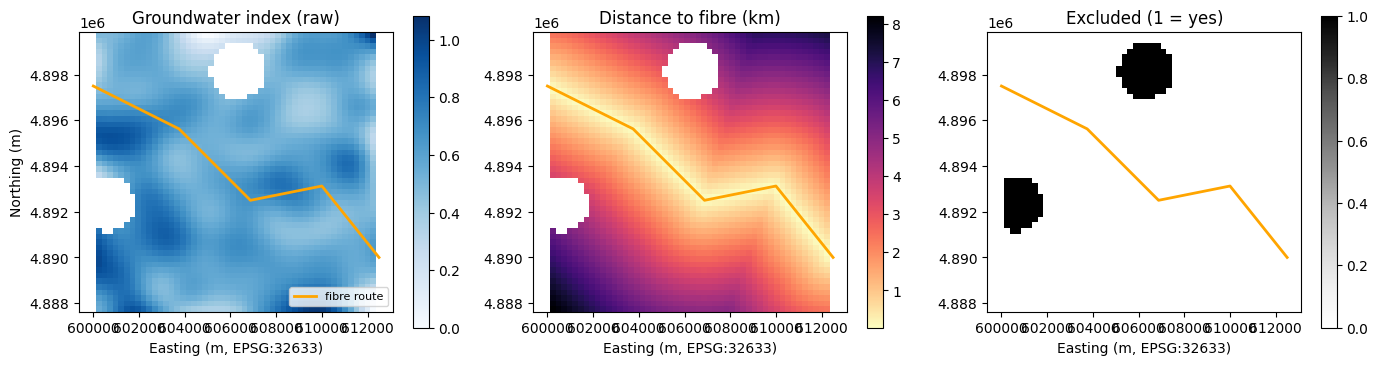

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
panels = [
    (gw_raw, "Groundwater index (raw)", "Blues"),
    (dist_m / 1000, "Distance to fibre (km)", "magma_r"),
    (excluded.astype(float), "Excluded (1 = yes)", "Greys"),
]
xs, ys = grid.cell_centres()
extent = [xs.min(), xs.max(), ys.min(), ys.max()]
for ax, (arr, title, cmap) in zip(axes, panels):
    im = ax.imshow(arr, cmap=cmap, extent=extent)
    route_xy = np.asarray(route.coords)
    ax.plot(route_xy[:, 0], route_xy[:, 1], color="orange", lw=2, label="fibre route")
    ax.set_title(title)
    ax.set_xlabel(f"Easting (m, {CRS})")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("Northing (m)")
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "input_layers.png", dpi=120)
plt.show()

## 4. Normalise and combine
Each layer is scaled to [0, 1] with higher meaning more suitable. Distance is inverted, so closer to fibre scores higher.

In [4]:
layers = {
    "groundwater": min_max(gw_raw),
    "fibre": proximity_score(dist_m),
}
score = weighted_overlay(layers, BASE_WEIGHTS)
print("Valid scored cells:", int(np.isfinite(score).sum()), "of", score.size)
print("Score range:", round(float(np.nanmin(score)), 3), "to", round(float(np.nanmax(score)), 3))

Valid scored cells: 2363 of 2500
Score range: 0.073 to 0.912


## 5. Top candidate cells under the base weights

In [5]:
top = top_k_cells(score, grid, TOP_K)
top

,rank,row,col,x_m,y_m,score
0,1,49,39,609875.0,4887625.0,0.911824
1,2,49,38,609625.0,4887625.0,0.904391
2,3,49,40,610125.0,4887625.0,0.902024
3,4,49,37,609375.0,4887625.0,0.884043
4,5,49,41,610375.0,4887625.0,0.871324
5,6,0,49,612375.0,4899875.0,0.869471
6,7,18,3,600875.0,4895375.0,0.868911
7,8,18,2,600625.0,4895375.0,0.868042
8,9,48,39,609875.0,4887875.0,0.866277
9,10,18,4,601125.0,4895375.0,0.865131


**Which layer drives the top sites?** The table decomposes the top-10 score into each layer's weighted contribution, and compares the top cells with the study-area average.

In [6]:
t_rows, t_cols = top["row"].to_numpy(), top["col"].to_numpy()
contrib_gw = BASE_WEIGHTS["groundwater"] * layers["groundwater"][t_rows, t_cols]
contrib_fib = BASE_WEIGHTS["fibre"] * layers["fibre"][t_rows, t_cols]
decomp = pd.DataFrame({
    "top10 mean": {
        "groundwater layer (0-1)": layers["groundwater"][t_rows, t_cols].mean(),
        "fibre layer (0-1)": layers["fibre"][t_rows, t_cols].mean(),
        "groundwater share of score (%)": 100 * (contrib_gw / (contrib_gw + contrib_fib)).mean(),
        "distance to route (km)": dist_m[t_rows, t_cols].mean() / 1000,
    },
    "all valid cells mean": {
        "groundwater layer (0-1)": np.nanmean(layers["groundwater"]),
        "fibre layer (0-1)": np.nanmean(layers["fibre"]),
        "groundwater share of score (%)": np.nan,
        "distance to route (km)": np.nanmean(dist_m) / 1000,
    },
}).round(2)
decomp

,top10 mean,all valid cells mean
groundwater layer (0-1),0.93,0.55
fibre layer (0-1),0.60,0.67
groundwater share of score (%),89.73,NaN
distance to route (km),3.28,2.72


## 6. Results map

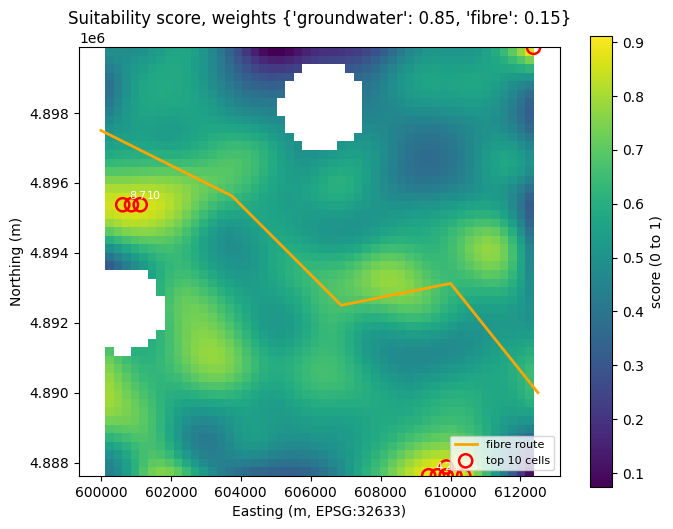

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(score, cmap="viridis", extent=extent)
ax.plot(route_xy[:, 0], route_xy[:, 1], color="orange", lw=2, label="fibre route")
ax.scatter(top["x_m"], top["y_m"], s=90, facecolors="none", edgecolors="red", lw=1.8,
           label=f"top {TOP_K} cells")
for _, row in top.iterrows():
    ax.annotate(str(int(row["rank"])), (row["x_m"], row["y_m"]), xytext=(5, 4),
                textcoords="offset points", color="white", fontsize=8)
ax.set_title(f"Suitability score, weights {BASE_WEIGHTS}")
ax.set_xlabel(f"Easting (m, {CRS})")
ax.set_ylabel("Northing (m)")
ax.legend(loc="lower right", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="score (0 to 1)")
fig.tight_layout()
fig.savefig(FIG_DIR / "suitability_top_sites.png", dpi=120)
plt.show()

## 7. Sensitivity of the ranking to the groundwater weight

The groundwater weight is swept from 0.5 to 1.0, with the fibre weight adjusted so the weights still sum to 1. For each setting the notebook reports the Spearman correlation with the base ranking over all valid cells, and the Jaccard overlap of the top-10 and top-25 sets with the base top sets.

In [8]:
values = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 1.00]
sweep10 = weight_sweep(layers, BASE_WEIGHTS, vary="groundwater", values=values, k=10)
sweep25 = weight_sweep(layers, BASE_WEIGHTS, vary="groundwater", values=values, k=25)
sweep = sweep10.rename(columns={"top_k_jaccard_vs_base": "jaccard_top10"}).merge(
    sweep25[["groundwater", "top_k_jaccard_vs_base"]].rename(columns={"top_k_jaccard_vs_base": "jaccard_top25"}),
    on="groundwater",
).round(3)
sweep

,groundwater,spearman_vs_base,jaccard_top10,jaccard_top25
0,0.50,0.668,0.000,0.163
1,0.60,0.787,0.176,0.351
2,0.70,0.910,0.250,0.562
3,0.80,0.989,0.667,0.852
4,0.85,1.000,1.000,1.000
5,0.90,0.990,0.667,0.923
6,1.00,0.931,0.538,0.471


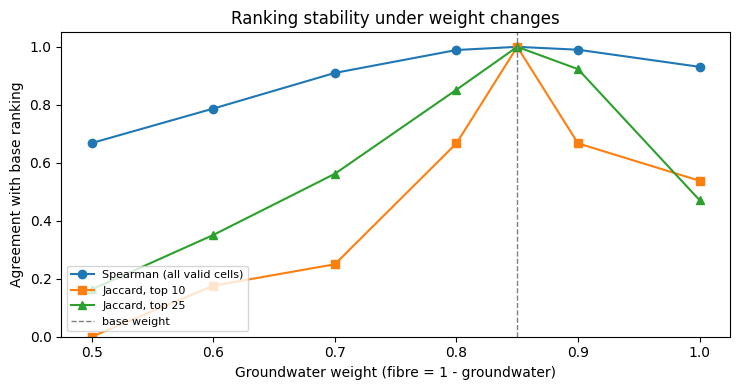

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(sweep["groundwater"], sweep["spearman_vs_base"], marker="o", label="Spearman (all valid cells)")
ax.plot(sweep["groundwater"], sweep["jaccard_top10"], marker="s", label="Jaccard, top 10")
ax.plot(sweep["groundwater"], sweep["jaccard_top25"], marker="^", label="Jaccard, top 25")
ax.axvline(BASE_WEIGHTS["groundwater"], color="grey", ls="--", lw=1, label="base weight")
ax.set_xlabel("Groundwater weight (fibre = 1 - groundwater)")
ax.set_ylabel("Agreement with base ranking")
ax.set_ylim(0, 1.05)
ax.set_title("Ranking stability under weight changes")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "weight_sensitivity.png", dpi=120)
plt.show()

## 8. Interpretation, limitations and next steps

**Result 1: the top of the ranking is concentrated in two patches.** Under the base weights (0.85 groundwater, 0.15 fibre), the top 10 cells fall in two areas: a western patch near the 602,000 m easting and a southern patch along the bottom row of the grid. Several are adjacent cells. So "top 10" describes about two candidate areas, not ten independent options. Any shortlist should be read as areas and checked against further data.

**Result 2: the top set depends strongly on the weights.** The Spearman correlation with the base ranking is 0.99 at a groundwater weight of 0.80 or 0.90, but the top-10 overlap is only 0.67 at either value. At 0.50 the top-10 overlap is 0. The full-grid ordering is more stable than the top of the list, which is the usual pattern: the bulk ranking moves slowly while the extreme cells change quickly. For practical decisions, the top-25 overlap (0.85 at 0.80 and 0.92 at 0.90) is more informative than the top-10 overlap.

**Result 3: the base weight is a judgement, and the sweep shows its effect.** The ranking is sharpest at the base weight by construction. Moving the groundwater weight by ±0.05 changes the top-10 set by about a third. The sweep does not say which weight is right. It shows how much the answer depends on that choice, which is what a stakeholder needs before a weighting is adopted.

**Result 4: the top sites are driven by groundwater, and fibre proximity does not favour them.** The decomposition table shows the top 10 cells have a mean groundwater layer score of 0.93, against 0.55 across all valid cells. Groundwater accounts for about 90% of their score. Their mean distance to the route is 3.3 km, which is further than the 2.7 km average across valid cells. The fibre layer therefore lowers their score slightly. This follows from the synthetic groundwater field sitting away from the route, and from the 0.85 weight. It is a property of these inputs, not a finding about real infrastructure, but it is the kind of conflict between criteria that a stakeholder should see before weights are fixed.

**Limitations**

- Every layer is synthetic, and the groundwater field has no physical basis. The results demonstrate the method, not any real site.
- Min-max normalisation depends on the study extent. Adding or removing area changes every score, so these scores are only comparable within this extent.
- The overlay is linear and fully compensating. A cell with very poor groundwater can be rescued by good fibre access. Real site criteria often need thresholds or constraints instead.
- Gaussian smoothing uses `mode="nearest"`, so edge cells take values from the boundary. The southern and western patches may partly reflect this edge effect.
- No costs, land ownership, zoning or water-rights constraints are included.

**Next steps**

- Replace the min-max scale with threshold or constraint layers, and compare the two.
- Add a random-weight (Dirichlet) sensitivity, which samples many weight sets at once rather than sweeping one weight.
- Report cells as contiguous areas (connected components) rather than individual cells, which would also make the stability results easier to read.